In [3]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
data_pre = pd.read_csv("WDICSV.csv")

#Loading Indicators
indicators = ['NY.GDP.PCAP.CD', 'NY.GDP.MKTP.KD.ZG', 'FP.CPI.TOTL.ZG', 'SL.UEM.TOTL.ZS', 'NE.TRD.GNFS.ZS', 'NE.GDI.TOTL.ZS', 'SP.DYN.LE00.IN', 'SP.URB.TOTL.IN.ZS', 'IT.NET.USER.ZS', 'EG.ELC.ACCS.ZS', 'SE.SEC.ENRR']

In [5]:
data_pre = data_pre[data_pre['Indicator Code'].isin(indicators)]
data_pre.isna().sum().sort_values()[:5]

Country Name        0
Country Code        0
Indicator Name      0
Indicator Code      0
2015              261
dtype: int64

In [6]:
#2015 has the least number of missing values
data_fil = data_pre.pivot_table(index=['Country Name', 'Country Code'], columns='Indicator Code', values='2015').reset_index()

In [7]:
print(len(data_fil))

265


In [8]:
url = 'https://api.worldbank.org/v2/country?format=json&per_page=400'
response = requests.get(url)
data_cat = response.json()

In [9]:
countries = pd.json_normalize(data_cat[1])
countries = countries.rename(columns = {'id' : 'Country Code'})
countries = countries[['Country Code','region.value','lendingType.value','incomeLevel.value']]
countries = countries[countries['region.value'] != 'Aggregates'] #removing aggregate rows

In [10]:
data = data_fil.merge(countries, on='Country Code', how='inner')
#This removed aggregates present in WDI data, since country codes for aggregates (like World, Upper high income) were removed and hence did not merge

In [11]:
data

,Country Name,Country Code,EG.ELC.ACCS.ZS,FP.CPI.TOTL.ZG,IT.NET.USER.ZS,NE.GDI.TOTL.ZS,NE.TRD.GNFS.ZS,NY.GDP.MKTP.KD.ZG,NY.GDP.PCAP.CD,SE.SEC.ENRR,SL.UEM.TOTL.ZS,SP.DYN.LE00.IN,SP.URB.TOTL.IN.ZS,region.value,lendingType.value,incomeLevel.value
0,Afghanistan,AFG,71.5,-0.661709,8.260000,NaN,NaN,1.451315,565.569730,53.150108,9.032,62.270000,24.464912,"Middle East, North Africa, Afghanistan & Pakistan",IDA,Low income
1,Albania,ALB,100.0,1.896174,56.900002,27.813465,71.279448,2.227704,4199.539129,102.440729,17.193,78.358000,55.157929,Europe & Central Asia,IBRD,Upper middle income
2,Algeria,DZA,99.4,4.784447,38.200001,51.779613,53.204623,3.200000,4685.059027,NaN,11.206,75.159000,70.143307,"Middle East, North Africa, Afghanistan & Pakistan",IBRD,Upper middle income
3,American Samoa,ASM,NaN,NaN,NaN,NaN,162.407132,3.149606,12727.410265,NaN,NaN,72.654000,84.668671,East Asia & Pacific,Not classified,High income
4,Andorra,AND,100.0,NaN,87.900002,NaN,NaN,1.434140,38654.934722,91.296219,NaN,84.532000,88.518085,Europe & Central Asia,Not classified,High income
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
212,Virgin Islands (U.S.),VIR,100.0,NaN,54.839137,NaN,84.766585,-0.425080,34007.352941,NaN,11.649,79.017073,94.941332,Latin America & Caribbean,Not classified,High income
213,West Bank and Gaza,PSE,99.9,1.431611,56.700001,25.088031,70.780968,3.721300,3272.154324,88.390922,23.005,74.577000,85.218217,"Middle East, North Africa, Afghanistan & Pakistan",Not classified,Lower middle income
214,"Yemen, Rep.",YEM,67.4,NaN,24.085400,1.656342,30.367659,-27.994546,1362.173812,NaN,17.900,66.761000,32.388318,"Middle East, North Africa, Afghanistan & Pakistan",IDA,Low income
215,Zambia,ZMB,31.1,10.110593,8.800000,42.805116,79.865269,2.920375,1295.877887,NaN,5.951,60.728000,41.955510,Sub-Saharan Africa,IDA,Lower middle income


## Exploratory Data Analysis

### 1. Data Inspection

In [12]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country Name       217 non-null    str    
 1   Country Code       217 non-null    str    
 2   EG.ELC.ACCS.ZS     215 non-null    float64
 3   FP.CPI.TOTL.ZG     189 non-null    float64
 4   IT.NET.USER.ZS     201 non-null    float64
 5   NE.GDI.TOTL.ZS     177 non-null    float64
 6   NE.TRD.GNFS.ZS     185 non-null    float64
 7   NY.GDP.MKTP.KD.ZG  211 non-null    float64
 8   NY.GDP.PCAP.CD     212 non-null    float64
 9   SE.SEC.ENRR        155 non-null    float64
 10  SL.UEM.TOTL.ZS     187 non-null    float64
 11  SP.DYN.LE00.IN     217 non-null    float64
 12  SP.URB.TOTL.IN.ZS  217 non-null    float64
 13  region.value       217 non-null    str    
 14  lendingType.value  217 non-null    str    
 15  incomeLevel.value  217 non-null    str    
dtypes: float64(11), str(5)
memory usage: 

### For 2015
There are 217 countries \
11 Indicators which will act as variables

```Missing values for countries (Out of 217) - 
2 in Electricity access    (0.9217%)
28 in Inflation            (12.9032%)
16 in Internet users       (7.3732%)
40 in GCF                  (18.4332%)
32 in Trade                (14.7465%)
6 in GDP Growth            (2.750%)
5 in GDP per Captita       (2.3041%)
62 in Secondary Enrollment (28.5714%)
30 in Unemployment         (13.8249%)
All data present for Life expectancy and Urban population

In [13]:
data.set_index('Country Name')[indicators].isna().sum(axis=1).sort_values(ascending=False)[:10] #Countries with the largest amount of missing data

Country Name
Gibraltar                    8
British Virgin Islands       7
St. Martin (French part)     7
Isle of Man                  6
American Samoa               6
Korea, Dem. People's Rep.    6
Liechtenstein                5
Channel Islands              5
Eritrea                      5
Monaco                       5
dtype: int64

In [14]:
data[indicators].describe().T

,count,mean,std,min,25%,50%,75%,max
NY.GDP.PCAP.CD,212.0,17068.360267,25280.529658,254.402585,2233.655343,6147.913295,20496.424748,170437.021129
NY.GDP.MKTP.KD.ZG,211.0,2.700007,4.509821,-27.994546,1.130550,2.920293,4.469767,24.623986
FP.CPI.TOTL.ZG,189.0,4.062122,10.975076,-3.749145,0.065290,1.437024,4.560563,121.738085
SL.UEM.TOTL.ZS,187.0,8.092743,6.015152,0.170000,3.884500,6.412000,10.754000,27.695000
NE.TRD.GNFS.ZS,185.0,89.998884,56.476070,18.378273,54.874951,74.634355,107.806616,389.405949
NE.GDI.TOTL.ZS,177.0,24.525446,9.083154,-3.945924,19.479615,23.859794,28.416408,76.782325
SP.DYN.LE00.IN,217.0,72.114401,8.223112,39.757000,66.023000,73.624390,78.275000,85.323000
SP.URB.TOTL.IN.ZS,217.0,60.447882,23.956429,13.234136,39.982442,61.737474,80.570799,100.000000
IT.NET.USER.ZS,201.0,47.857891,29.000793,1.083700,21.320000,50.139318,72.049400,98.323610
EG.ELC.ACCS.ZS,215.0,83.290233,27.086065,4.800000,73.900000,99.400000,100.000000,100.000000


In [15]:
(data[indicators].max() - data[indicators].min()).sort_values(ascending=False)

NY.GDP.PCAP.CD       170182.618543
NE.TRD.GNFS.ZS          371.027676
SE.SEC.ENRR             152.545009
FP.CPI.TOTL.ZG          125.487231
IT.NET.USER.ZS           97.239910
EG.ELC.ACCS.ZS           95.200000
SP.URB.TOTL.IN.ZS        86.765864
NE.GDI.TOTL.ZS           80.728249
NY.GDP.MKTP.KD.ZG        52.618532
SP.DYN.LE00.IN           45.566000
SL.UEM.TOTL.ZS           27.525000
dtype: float64

In [16]:
for col in indicators:
    print("Indicator - " + col + "\nLowest 3:")
    print(data[['Country Name', col]].sort_values(col)[:3])
    print("\n" + "Highest 3:")
    print(data[['Country Name', col]].sort_values(col, ascending=False)[:3])
    print()

Indicator - NY.GDP.PCAP.CD
Lowest 3:
                 Country Name  NY.GDP.PCAP.CD
31                    Burundi      254.402585
37   Central African Republic      366.322854
118                Madagascar      445.320069

Highest 3:
      Country Name  NY.GDP.PCAP.CD
130         Monaco   170437.021129
114  Liechtenstein   167187.157310
116     Luxembourg   105462.012584

Indicator - NY.GDP.MKTP.KD.ZG
Lowest 3:
         Country Name  NY.GDP.MKTP.KD.ZG
214       Yemen, Rep.         -27.994546
117  Macao SAR, China         -21.754008
178       South Sudan         -10.793365

Highest 3:
                 Country Name  NY.GDP.MKTP.KD.ZG
93                    Ireland          24.623986
200  Turks and Caicos Islands          11.314829
102                  Kiribati          11.265321

Indicator - FP.CPI.TOTL.ZG
Lowest 3:
       Country Name  FP.CPI.TOTL.ZG
110         Lebanon       -3.749145
216        Zimbabwe       -2.430968
36   Cayman Islands       -2.347528

Highest 3:
      Country Name  

GDP per capita has a large range: Burundi - least ($254), Monaco - largest ($170437)\
and so does GDP Growth: Yemen - least (-28%), Ireland - highest (24.62%)

South Sudan has just 4.8% electricity access, while several economies have reached 100%.\
Hong Kong has very high trade (389.41%) while lebanon got low (18.38%) trade\
Similarly Belgium has high (164.08%) secondary enrollement and South Sedan has it low (11.53%)

### 2. Analysis of feature Distributions

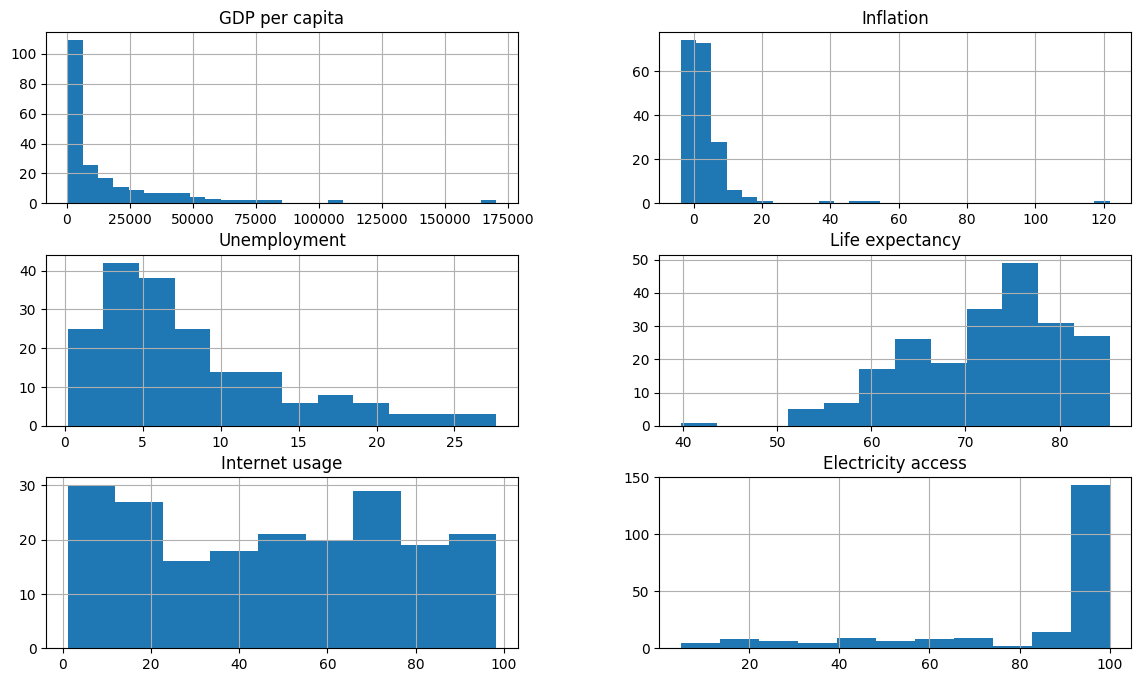

In [17]:
key_data = data[['NY.GDP.PCAP.CD', 'FP.CPI.TOTL.ZG', 'SL.UEM.TOTL.ZS', 'SP.DYN.LE00.IN', 'IT.NET.USER.ZS', 'EG.ELC.ACCS.ZS']]
key_data.rename(columns={'NY.GDP.PCAP.CD': 'GDP per capita', 'FP.CPI.TOTL.ZG': 'Inflation', 'SL.UEM.TOTL.ZS': 'Unemployment', 'SP.DYN.LE00.IN': 'Life expectancy', 'IT.NET.USER.ZS': 'Internet usage', 'EG.ELC.ACCS.ZS': 'Electricity access'}).hist(bins='auto', figsize=(14, 8));

Clearly GDP per capita, Inflation and Electricity access are extremely skewed\
GDP PC and Inflation are right skewed while Electricity access is left skewed

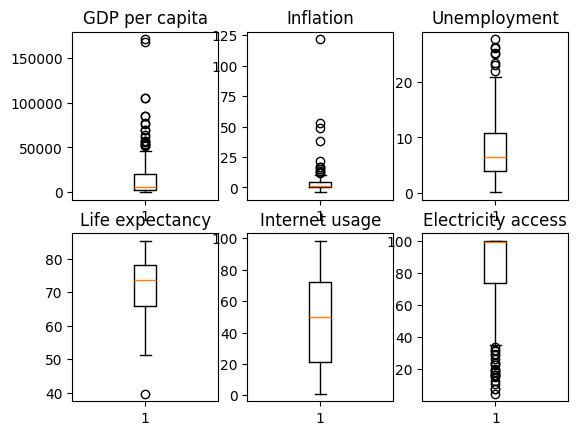

In [18]:
for i, col in enumerate(key_data.columns):
    plt.subplot(2, 3, i+1)
    plt.boxplot(key_data[col].dropna()) #since NaNs are present, boxplot wont give correct plot without dropna to remove NaNs
    plt.title(['GDP per capita', 'Inflation', 'Unemployment', 'Life expectancy', 'Internet usage', 'Electricity access'][i]);

The strongly skewed Indicators have large number of outliers, since their median is concentrated to one side
Life expectancy has just 1 outlier country - South Sudan (shown below)
Internet usage has no outliers.

In [19]:
q1, q3 = np.percentile(data['SP.DYN.LE00.IN'].dropna(), [25, 75])
iqr = q3 - q1
lower = q1 - 1.5 * iqr
data[data['SP.DYN.LE00.IN'] < lower][['Country Name', 'SP.DYN.LE00.IN']]

,Country Name,SP.DYN.LE00.IN
178,South Sudan,39.757


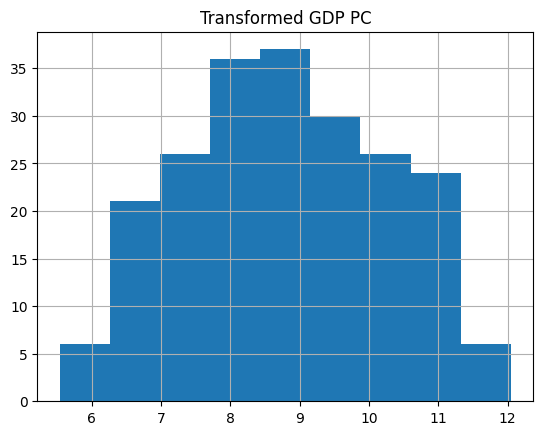

In [20]:
ln_trans_gdp = np.log(data['NY.GDP.PCAP.CD'].dropna())
ln_trans_gdp.hist(bins = 'auto').set_title('Transformed GDP PC');


The highly right skewed GDP PC indicator on applying log transformation (natural ln), made it symmetric (as seen from above histogram) and hence reduced the skewness. Hence using transformed GDP would be more useful for our clustering, since the really high GDP PC countries would not have a huge influence on the squared distance.

### 3. Comparision of known income groups

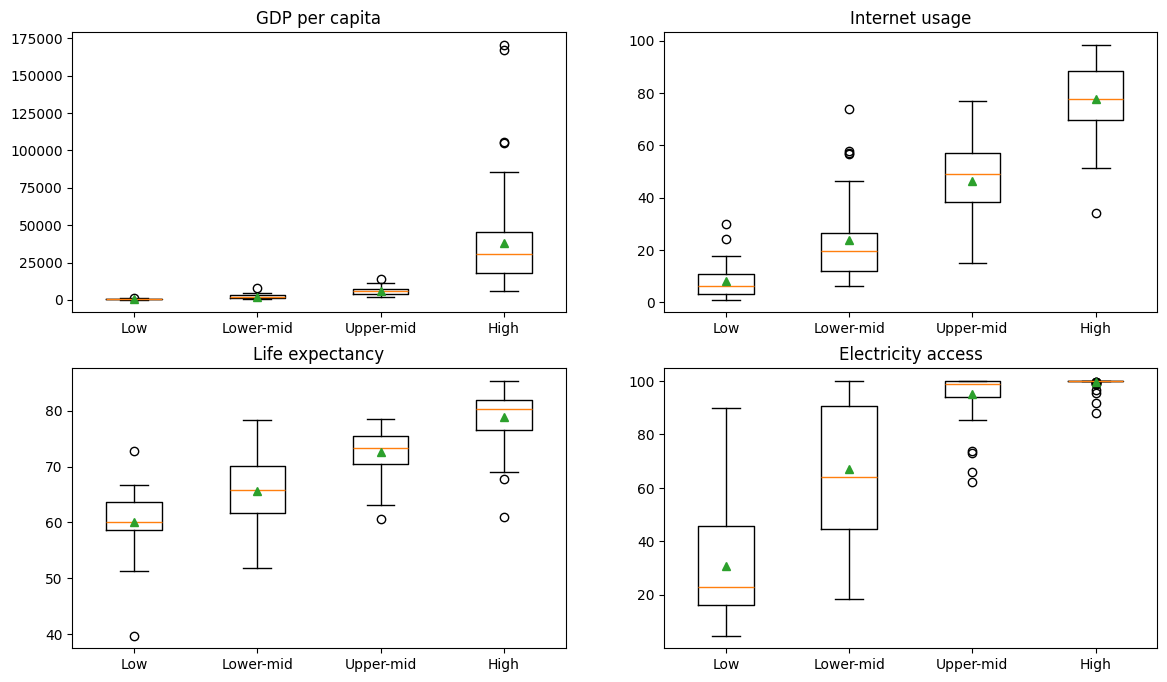

In [21]:
plt.figure(figsize=(14, 8))

for i, col in enumerate(['NY.GDP.PCAP.CD', 'IT.NET.USER.ZS', 'SP.DYN.LE00.IN', 'EG.ELC.ACCS.ZS']):
    plt.subplot(2, 2, i+1)

    plt.boxplot([data[data['incomeLevel.value'] == 'Low income'][col].dropna(), data[data['incomeLevel.value'] == 'Lower middle income'][col].dropna(), data[data['incomeLevel.value'] == 'Upper middle income'][col].dropna(), data[data['incomeLevel.value'] == 'High income'][col].dropna()], tick_labels=['Low', 'Lower-mid', 'Upper-mid', 'High'], showmeans = True)

    plt.title(['GDP per capita', 'Internet usage', 'Life expectancy', 'Electricity access'][i])


Clearly for all 4 Indicators, High income countries (as classified by World Bank), have higher mean and median and they reduce as we move towards Low income countries.

### 4. Correlations between Indicators

In [22]:
corr = data[indicators].corr(method='pearson')
corr

,NY.GDP.PCAP.CD,NY.GDP.MKTP.KD.ZG,FP.CPI.TOTL.ZG,SL.UEM.TOTL.ZS,NE.TRD.GNFS.ZS,NE.GDI.TOTL.ZS,SP.DYN.LE00.IN,SP.URB.TOTL.IN.ZS,IT.NET.USER.ZS,EG.ELC.ACCS.ZS,SE.SEC.ENRR
NY.GDP.PCAP.CD,1.000000,-0.065625,-0.181044,-0.108601,0.364430,-0.101104,0.596484,0.430247,0.679852,0.375072,0.488621
NY.GDP.MKTP.KD.ZG,-0.065625,1.000000,-0.347511,-0.146928,0.115576,0.266027,-0.013631,-0.151636,-0.103582,-0.044329,-0.081862
FP.CPI.TOTL.ZG,-0.181044,-0.347511,1.000000,-0.014079,-0.141672,-0.089664,-0.219625,-0.007169,-0.153161,-0.124040,-0.172469
SL.UEM.TOTL.ZS,-0.108601,-0.146928,-0.014079,1.000000,0.033877,-0.154466,0.007691,0.103265,0.077823,0.139301,0.176846
NE.TRD.GNFS.ZS,0.364430,0.115576,-0.141672,0.033877,1.000000,-0.048187,0.284006,0.294384,0.346294,0.241397,0.276494
NE.GDI.TOTL.ZS,-0.101104,0.266027,-0.089664,-0.154466,-0.048187,1.000000,-0.007107,-0.132357,-0.085404,-0.008324,-0.116948
SP.DYN.LE00.IN,0.596484,-0.013631,-0.219625,0.007691,0.284006,-0.007107,1.000000,0.605656,0.851388,0.802864,0.792618
SP.URB.TOTL.IN.ZS,0.430247,-0.151636,-0.007169,0.103265,0.294384,-0.132357,0.605656,1.000000,0.690277,0.576834,0.572853
IT.NET.USER.ZS,0.679852,-0.103582,-0.153161,0.077823,0.346294,-0.085404,0.851388,0.690277,1.000000,0.754603,0.808816
EG.ELC.ACCS.ZS,0.375072,-0.044329,-0.124040,0.139301,0.241397,-0.008324,0.802864,0.576834,0.754603,1.000000,0.795080


From the table, it can be observed that GDP PC, Life expectancy and Internet Users have generally high correlations with other Indicators

Text(0.5, 1.0, 'Correlation Matrix')

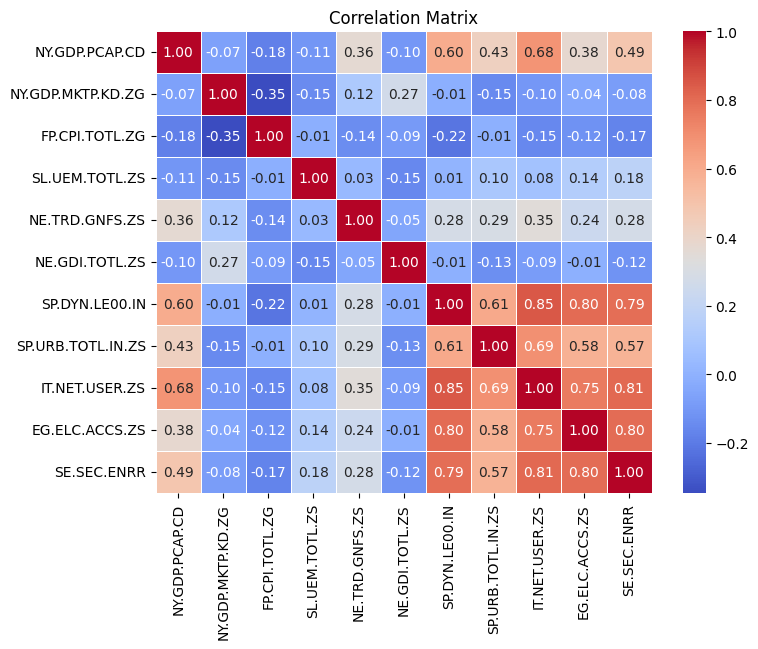

In [23]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix')

(-1.0, 1.0)

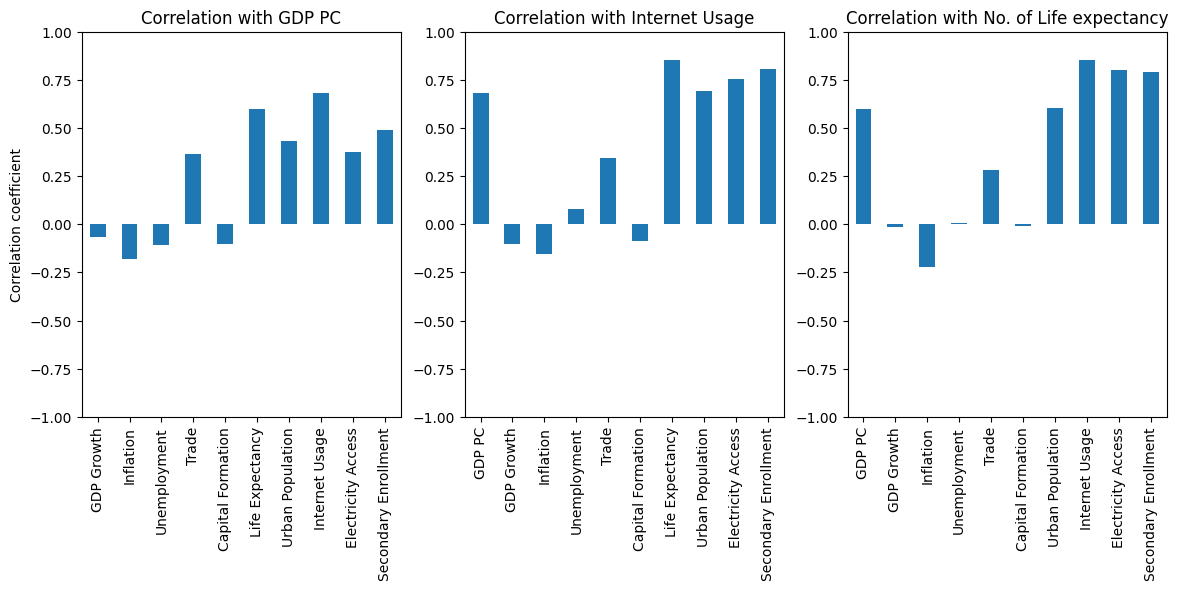

In [24]:
plt.figure(figsize=(14,5))
plt.subplot(1, 3, 1)
corr['NY.GDP.PCAP.CD'].drop('NY.GDP.PCAP.CD').rename(index={'NY.GDP.MKTP.KD.ZG': 'GDP Growth', 'FP.CPI.TOTL.ZG': 'Inflation', 'SL.UEM.TOTL.ZS': 'Unemployment', 'NE.TRD.GNFS.ZS': 'Trade', 'NE.GDI.TOTL.ZS': 'Capital Formation', 'SP.DYN.LE00.IN': 'Life Expectancy', 'SP.URB.TOTL.IN.ZS': 'Urban Population', 'IT.NET.USER.ZS': 'Internet Usage', 'EG.ELC.ACCS.ZS': 'Electricity Access', 'SE.SEC.ENRR': 'Secondary Enrollment'}).plot.bar()
#drop removes the row with same indicator (giving correlation 1)
plt.title('Correlation with GDP PC')
plt.ylabel('Correlation coefficient')
plt.ylim(-1, 1)

plt.subplot(1, 3, 2)
corr['IT.NET.USER.ZS'].drop('IT.NET.USER.ZS').rename(index={'NY.GDP.PCAP.CD': 'GDP PC', 'NY.GDP.MKTP.KD.ZG': 'GDP Growth', 'FP.CPI.TOTL.ZG': 'Inflation', 'SL.UEM.TOTL.ZS': 'Unemployment', 'NE.TRD.GNFS.ZS': 'Trade', 'NE.GDI.TOTL.ZS': 'Capital Formation', 'SP.DYN.LE00.IN': 'Life Expectancy', 'SP.URB.TOTL.IN.ZS': 'Urban Population', 'EG.ELC.ACCS.ZS': 'Electricity Access', 'SE.SEC.ENRR': 'Secondary Enrollment'}).plot.bar()
plt.title('Correlation with Internet Usage')
plt.ylim(-1, 1)

plt.subplot(1, 3, 3)
corr['SP.DYN.LE00.IN'].drop('SP.DYN.LE00.IN').rename(index={'NY.GDP.PCAP.CD': 'GDP PC', 'NY.GDP.MKTP.KD.ZG': 'GDP Growth', 'FP.CPI.TOTL.ZG': 'Inflation', 'SL.UEM.TOTL.ZS': 'Unemployment', 'NE.TRD.GNFS.ZS': 'Trade', 'NE.GDI.TOTL.ZS': 'Capital Formation', 'SP.URB.TOTL.IN.ZS': 'Urban Population', 'IT.NET.USER.ZS': 'Internet Usage', 'EG.ELC.ACCS.ZS': 'Electricity Access', 'SE.SEC.ENRR': 'Secondary Enrollment'}).plot.bar()
plt.title('Correlation with No. of Life expectancy')
plt.ylim(-1, 1)

We can see that GDP is highly correlated to Internet Users and Life Expectancy. This is expected as countries with high average income, have more people who can access the internet and healthcare facilities hence having higher life expectancy. It has weak correlations with GDP growth, Inflation and Unemployment.

Internet usage and Life expectancy are even more strongly correlated with each other, and both show strong correlations with Electricity access and Secondary enrollment. GDP growth, inflation and capital formation show relatively weak correlations with most of these indicators.

The strong correlations between some indicators could indicate redundancy.

### 5. Pairwise Relationships

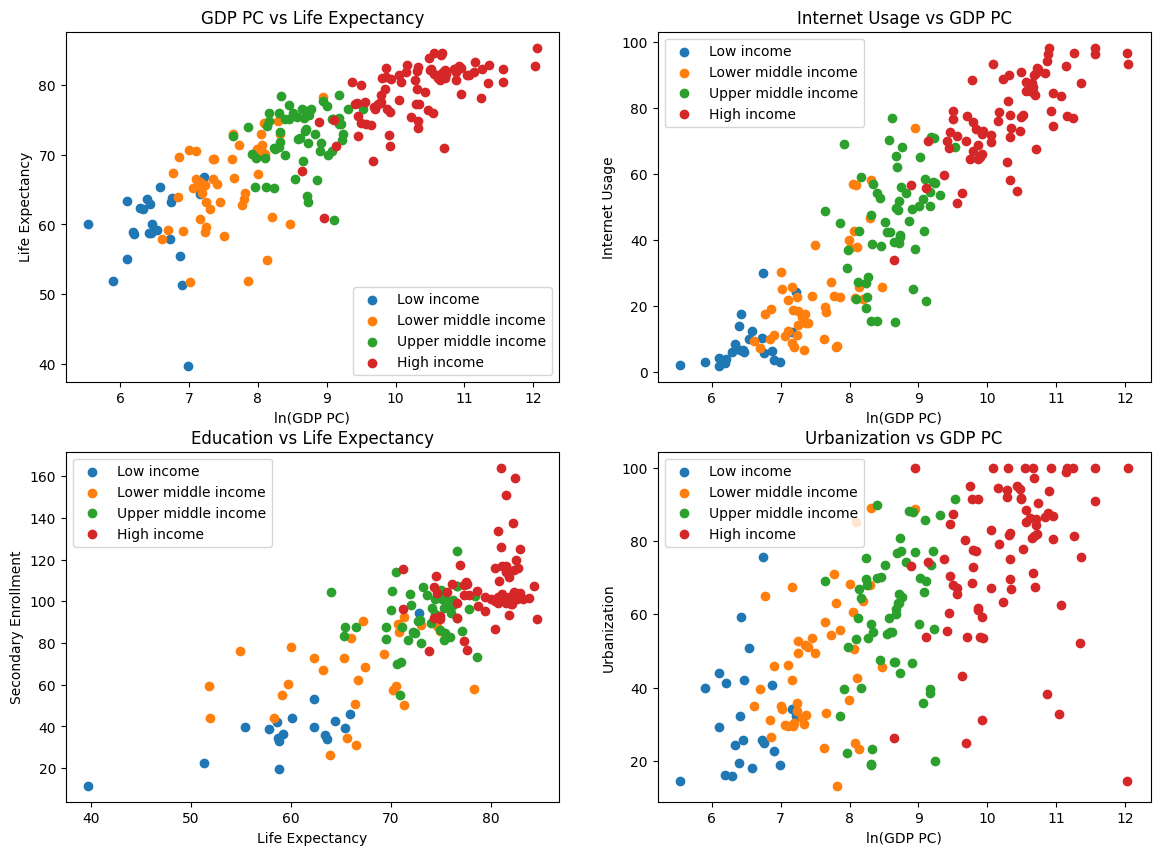

In [25]:
plt.figure(figsize=(14, 10))

for group in ['Low income', 'Lower middle income', 'Upper middle income', 'High income']:

    plt.subplot(2, 2, 1)
    plt.scatter(np.log(data[data['incomeLevel.value'] == group]['NY.GDP.PCAP.CD']), data[data['incomeLevel.value'] == group]['SP.DYN.LE00.IN'], label=group)
    plt.title('GDP PC vs Life Expectancy')
    plt.xlabel('ln(GDP PC)')
    plt.ylabel('Life Expectancy')
    plt.legend()

    plt.subplot(2, 2, 2)
    plt.scatter(np.log(data[data['incomeLevel.value'] == group]['NY.GDP.PCAP.CD']), data[data['incomeLevel.value'] == group]['IT.NET.USER.ZS'], label=group)
    plt.title('Internet Usage vs GDP PC')
    plt.xlabel('ln(GDP PC)')
    plt.ylabel('Internet Usage')
    plt.legend()

    plt.subplot(2, 2, 3)
    plt.scatter(data[data['incomeLevel.value'] == group]['SP.DYN.LE00.IN'], data[data['incomeLevel.value'] == group]['SE.SEC.ENRR'], label=group)
    plt.title('Education vs Life Expectancy')
    plt.xlabel('Life Expectancy')
    plt.ylabel('Secondary Enrollment')
    plt.legend()

    plt.subplot(2, 2, 4)
    plt.scatter(np.log(data[data['incomeLevel.value'] == group]['NY.GDP.PCAP.CD']), data[data['incomeLevel.value'] == group]['SP.URB.TOTL.IN.ZS'], label=group)
    plt.title('Urbanization vs GDP PC')
    plt.xlabel('ln(GDP PC)')
    plt.ylabel('Urbanization')
    plt.legend()

    #We had to take Transformed GDP PC because normally it was showing a heavily skewed plot where most values were concentrated to the left

All plots show a positive relationship between the Indicators. First plot shows Life expectancy increases with income, but the increase appears to slow down among high income countries.\
Low income countries having low internet usage and high income countries generally having much higher usage.\
Same can be seen with countries with higher secondary enrollment which generally have higher life expectancy, although it has some variation for high income countries.\
Urbanization is a more scattered plot indicating even some high income countries can have low urban population

### Data Preprocessing

In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer

In [31]:
impute = SimpleImputer(strategy='median')
X = data[indicators] 

X['NY.GDP.PCAP.CD'] = np.log(X['NY.GDP.PCAP.CD'])
#Using log (natural ln) transformed, makes the shape symmeteric ensuring extremely skewed GDP countries do not have high in influence their PCA/KMeans analysis.

X = impute.fit_transform(X)
#First we fill up NaN values using median imputation, i.e, put median instead of NaNs
#We used median because our data contains extreme skewed columns

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [34]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)
pca.explained_variance_ratio_

array([0.42390455, 0.13892617, 0.09425774, 0.08467748, 0.07436386,
       0.0557128 , 0.04518969, 0.03413676, 0.02602876, 0.01332624,
       0.00947595])